# Xenium Prime 5K Breast — expression-only GNN communication niches

Select the **cccphe** kernel and use **Run All**. This notebook invokes existing project modules to prepare and audit the real inputs, train the current model when needed, and display its results. A complete result with matching configuration is reused. New outputs are independent of archived AE/GNN results and remain on NAS. This is an independent downstream single-tissue analysis; no clinical/phenotype/TLS supervision enters the clinical CCC/Cox mainline.

Current configuration uses lambda_comp=0.005 and an independent NAS output directory. For the matched CCC-only ablation, change CONFIG to config/gnn_ccc_only.json and Restart Kernel / Run All. Previously displayed outputs belong to the earlier run; archived results and checkpoints are preserved.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.gnn.config import GNNConfig
from phenoniche.ccc.config import default_config
from phenoniche.gnn.pipeline import ensure_results
from phenoniche.gnn.reporting import GNNReport
CONFIG=ROOT/'config/gnn.json'
config=GNNConfig.from_json(CONFIG)
OUTPUT=Path(config.output_dir)
pd.set_option('display.max_colwidth',150)
pd.set_option('display.max_rows',200)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. Real data and model configuration

The current LR expression coverage filter is 5%. The encoder receives expression and geometry only. Cell types supply CCC and composition targets and downstream annotations. Expression normalization, feature scaling, and the effective CCC mask are fitted only on training spatial blocks. No CollecTRI/NicheNet supervision or regulatory target holdout is used.

In [2]:
input_config=default_config()
adata=ad.read_h5ad(input_config.processed_h5ad,backed='r')
try:
    display(pd.Series({'cells':adata.n_obs,'panel_genes':adata.n_vars,'dataset':adata.uns.get('dataset'),'expression_coverage_fraction':input_config.expression_coverage_fraction}).to_frame('Input'))
finally:
    adata.file.close()
display(pd.Series(config.to_dict()).to_frame('Model configuration'))
print('NAS outputs:',OUTPUT)

,Input
cells,699110
panel_genes,5101
dataset,Xenium_Prime_Breast_Cancer_FFPE
expression_coverage_fraction,0.05


,Model configuration
seed,40700
split_seed,40700
programs,32
hidden,64
encoder_genes,512
batch_size,512
max_epochs,40
patience,6
lr,0.003
weight_decay,0.0001


NAS outputs: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_composition_weak_expr05


## 2. Prepare, audit, train/reuse, and infer

This cell performs the actual workflow when Run All is requested. It constructs the unchanged directed CCC target if needed, replays outcome-blind broad cell labels, verifies cell order and exact physical-pair CCC, and applies the repository audit gate. Spatial block splitting purges neighborhoods crossing folds. The model is trained only when complete matching results are absent; saved compatible checkpoints can finish interrupted result export. Existing incompatible checkpoints are protected.

$Z=ap$, $p=\mathrm{Softmax}(f(G))$, $\hat C=ZH$, $\hat\pi=pB$. H and B are nonnegative, separately learned dictionaries with unit row sums. $\pi_t=\sum_{u:type(u)=t}\sum_{v\ne u}w_{uv}/\sum_u\sum_{v\ne u}w_{uv}$.

$L=L_{CCC}+\lambda_{comp}KL(\pi\Vert\hat\pi)+\lambda_{reg}L_{reg}$. CCC remains the primary objective; auxiliary gradient conflicts are projected against the CCC gradient.

Zero-opportunity microenvironments have undefined composition: their composition supervision and metrics are masked, while the original CCC target remains unchanged. Counts are recorded in cache/audit.json and training records.

In [3]:
summary=ensure_results(CONFIG)
report=GNNReport(OUTPUT)
display(report.overview())
display(report.features.head(12))
display(pd.Series(summary).to_frame('Saved analysis summary'))

Undefined composition for 17 centers with zero physical-pair opportunity; skipping their composition supervision
Static graph inputs resident on cuda:0
Epoch 1/40
Epoch 1: train CCC=0.082604, validation CCC=0.076768, selected loss=0.080666
Epoch 2/40
Epoch 2: train CCC=0.081983, validation CCC=0.076533, selected loss=0.079377
Epoch 3/40
Epoch 3: train CCC=0.081718, validation CCC=0.076441, selected loss=0.079045
Epoch 4/40
Epoch 4: train CCC=0.081539, validation CCC=0.076394, selected loss=0.078744
Epoch 5/40
Epoch 5: train CCC=0.081426, validation CCC=0.076312, selected loss=0.078502
Epoch 6/40
Epoch 6: train CCC=0.081337, validation CCC=0.076291, selected loss=0.078433
Epoch 7/40
Epoch 7: train CCC=0.081275, validation CCC=0.076290, selected loss=0.078391
Epoch 8/40
Epoch 8: train CCC=0.081230, validation CCC=0.076290, selected loss=0.078350
Epoch 9/40
Epoch 9: train CCC=0.081195, validation CCC=0.076323, selected loss=0.078428
Epoch 10/40
Epoch 10: train CCC=0.081163, validation CCC

,Value
Cells / microenvironments,699110
Xenium genes,5101
Fixed directed CCC features,2374
Effective training features,1821
Expression input genes,512
Cell-type encoder input,False
Communication programs,32
Selected niches,4
Composition weight,0.005
Undefined composition centers (masked),17


,feature_id,flat_feature_index,sender,receiver,lr_id,ligand,receptor,ccc
0,0,2085,B cell,B cell,CommuSpace_HS_06177,PKM,CD44,B cell → B cell | PKM–CD44
1,1,2348,B cell,B cell,CommuSpace_HS_06996,SLAMF7,SLAMF7,B cell → B cell | SLAMF7–SLAMF7
2,2,2547,B cell,B cell,CommuSpace_HS_07452,TIMP3,CD44,B cell → B cell | TIMP3–CD44
3,3,3014,B cell,Endothelial,CommuSpace_HS_00413,ARF1,INSR,B cell → Endothelial | ARF1–INSR
4,4,3340,B cell,Endothelial,CommuSpace_HS_01181,CD44,SELE,B cell → Endothelial | CD44–SELE
5,5,3655,B cell,Endothelial,CommuSpace_HS_02342,DCN,KDR,B cell → Endothelial | DCN–KDR
6,6,4240,B cell,Endothelial,CommuSpace_HS_03965,GNAI2,F2R,B cell → Endothelial | GNAI2–F2R
7,7,4251,B cell,Endothelial,CommuSpace_HS_03976,GNAI2,S1PR1,B cell → Endothelial | GNAI2–S1PR1
8,8,4794,B cell,Endothelial,CommuSpace_HS_05571,NAMPT,INSR,B cell → Endothelial | NAMPT–INSR
9,9,4795,B cell,Endothelial,CommuSpace_HS_05572,NAMPT,ITGA5,B cell → Endothelial | NAMPT–ITGA5


,Saved analysis summary
composition_undefined_centers,17
composition_to_Z_test_R2,0.398852
composition_only_niche_test_accuracy,0.872384
dominant_niche_test_fraction,0.386418
test_spatial_neighbor_agreement,0.936254
effective_programs,11.797546
maximum_dictionary_cosine,0.542709
dictionary_entropy,1.111073
interpretation,"Single-tissue association diagnostics; composition is auxiliary supervision, not evidence of causality or phenotype."
selected_K,4


## 3. Training curves and held-out CCC/composition reconstruction

Train/validation/test centers do not share physical cells. Composition values are weighted by the original directed physical cell-pair weights, not by center-cell labels or a separate neighborhood definition.

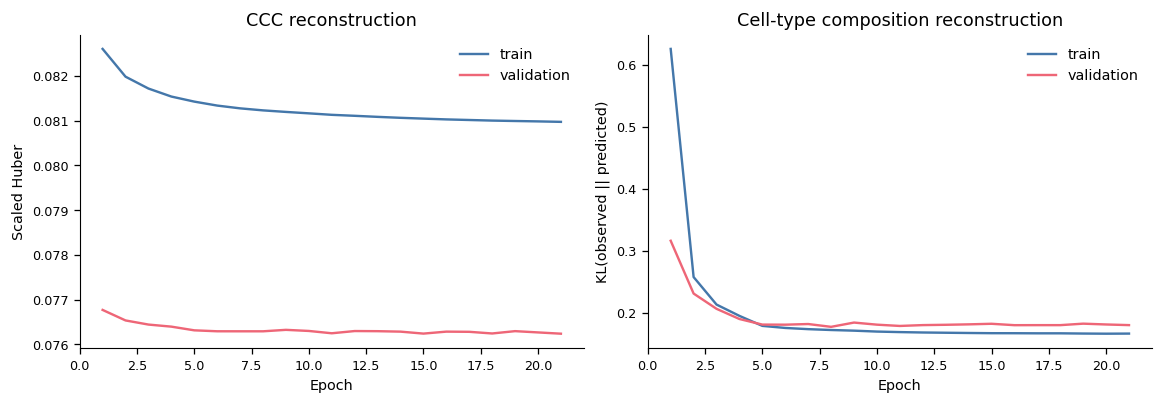

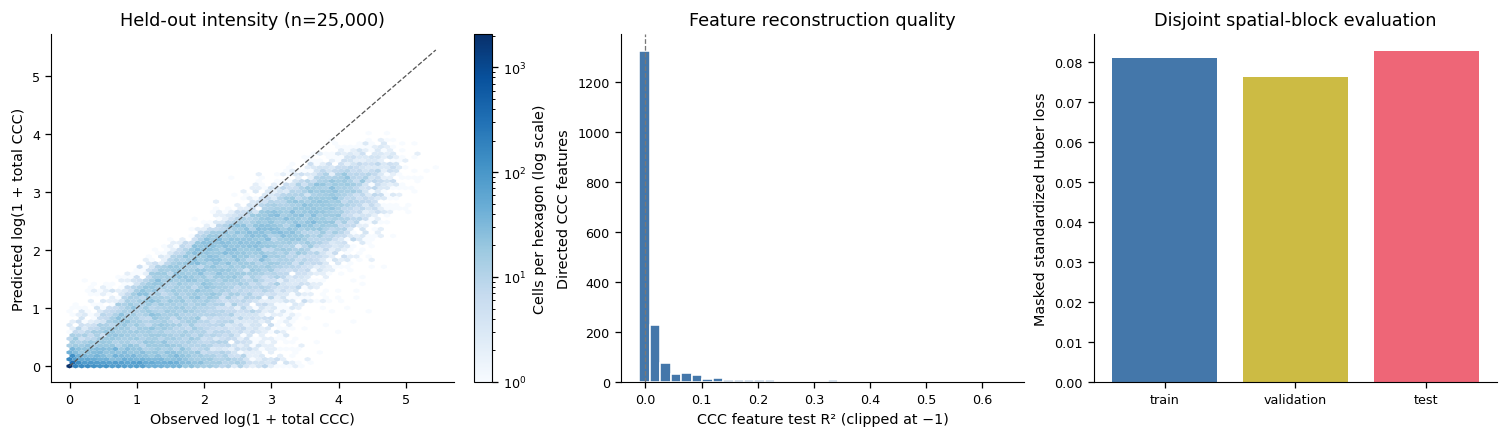

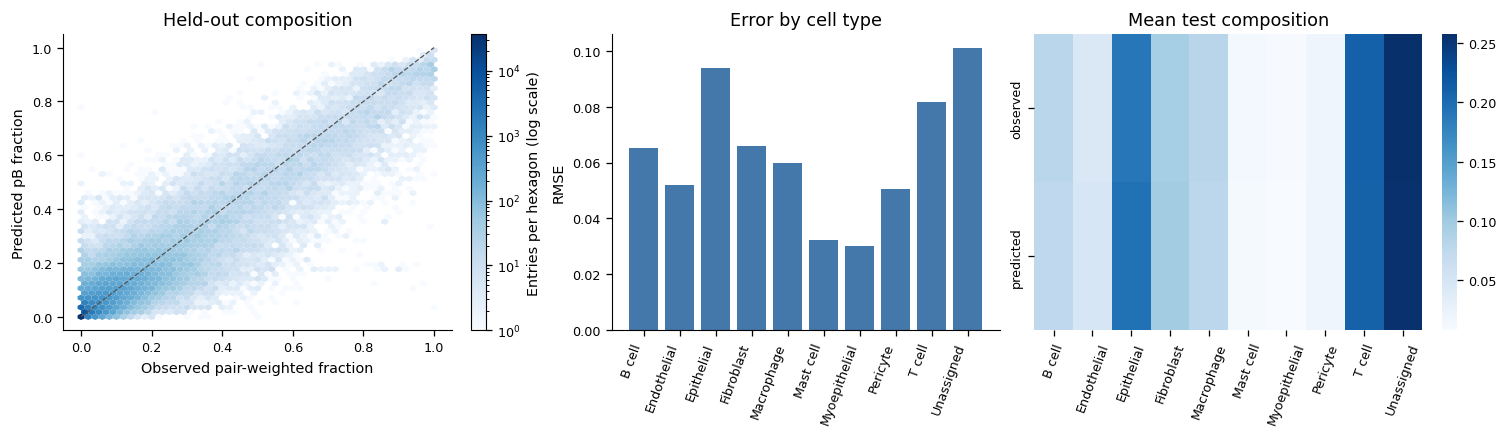

,n,scaled_huber,median_feature_R2,composition_valid_n,composition_KL,composition_RMSE
train,359883.0,0.081013,0.000561,359880.0,0.168089,0.064044
validation,107313.0,0.076239,0.000266,107313.0,0.182210,0.065868
test,112368.0,0.082900,0.000163,112368.0,0.182708,0.067349


,Held-out evaluation
best_epoch,15
validation_loss,0.078294
test,"{'ccc': 0.08290037827808412, 'composition': 0.18270798085439618, 'regularization': 0.23724698196504082, 'total': 0.08500015309218131, 'composition..."


In [4]:
show(report.training_curves())
show(report.reconstruction())
show(report.composition_reconstruction())
display(pd.DataFrame(report.reconstruction_metrics).T)
display(pd.Series(json.loads((OUTPUT/'heldout_metrics.json').read_text())).to_frame('Held-out evaluation'))

## 4. All 32 communication programs, CCC dictionary H, composition dictionary B

Absolute Z preserves total communication activity; P describes relative program composition. H traces each program to sender → receiver → LR features. Each row of B describes the typical cell-type mixture associated with one communication program; B is an auxiliary decoder, not an encoder input. The H heatmap highlights representative features; the full H is exported as CSV.

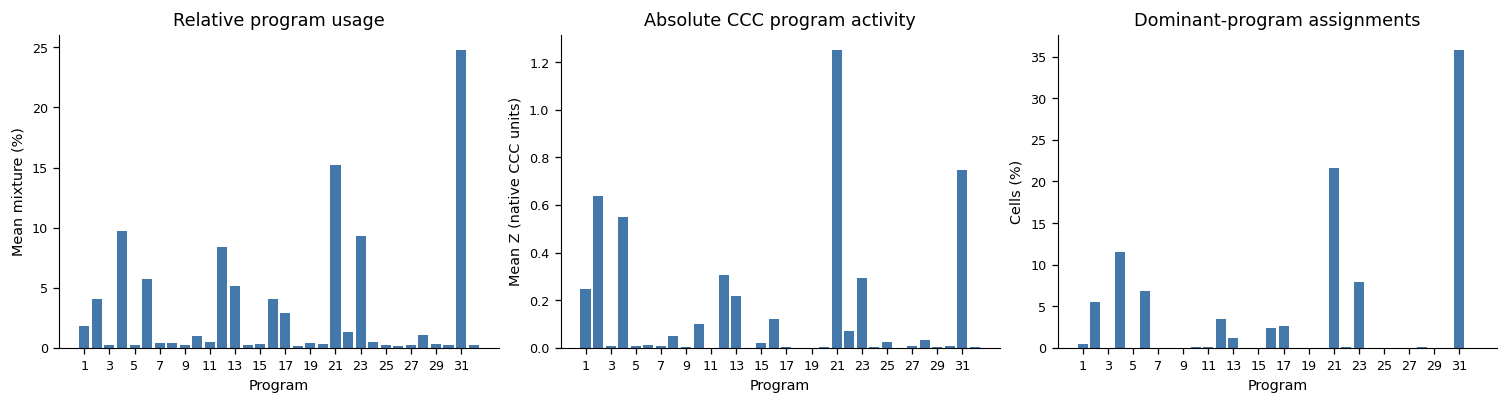

,program,mean_mixture,mean_exposure,dominant_fraction
0,1,0.018203,0.245900,0.004388
1,2,0.040826,0.639186,0.054831
2,3,0.002332,0.006806,0.000062
3,4,0.096931,0.551597,0.115859
4,5,0.002355,0.006061,0.000011
5,6,0.057354,0.012370,0.068201
6,7,0.003798,0.009106,0.000006
7,8,0.003995,0.049401,0.000099
8,9,0.002586,0.003904,0.000007
9,10,0.009546,0.099370,0.001280


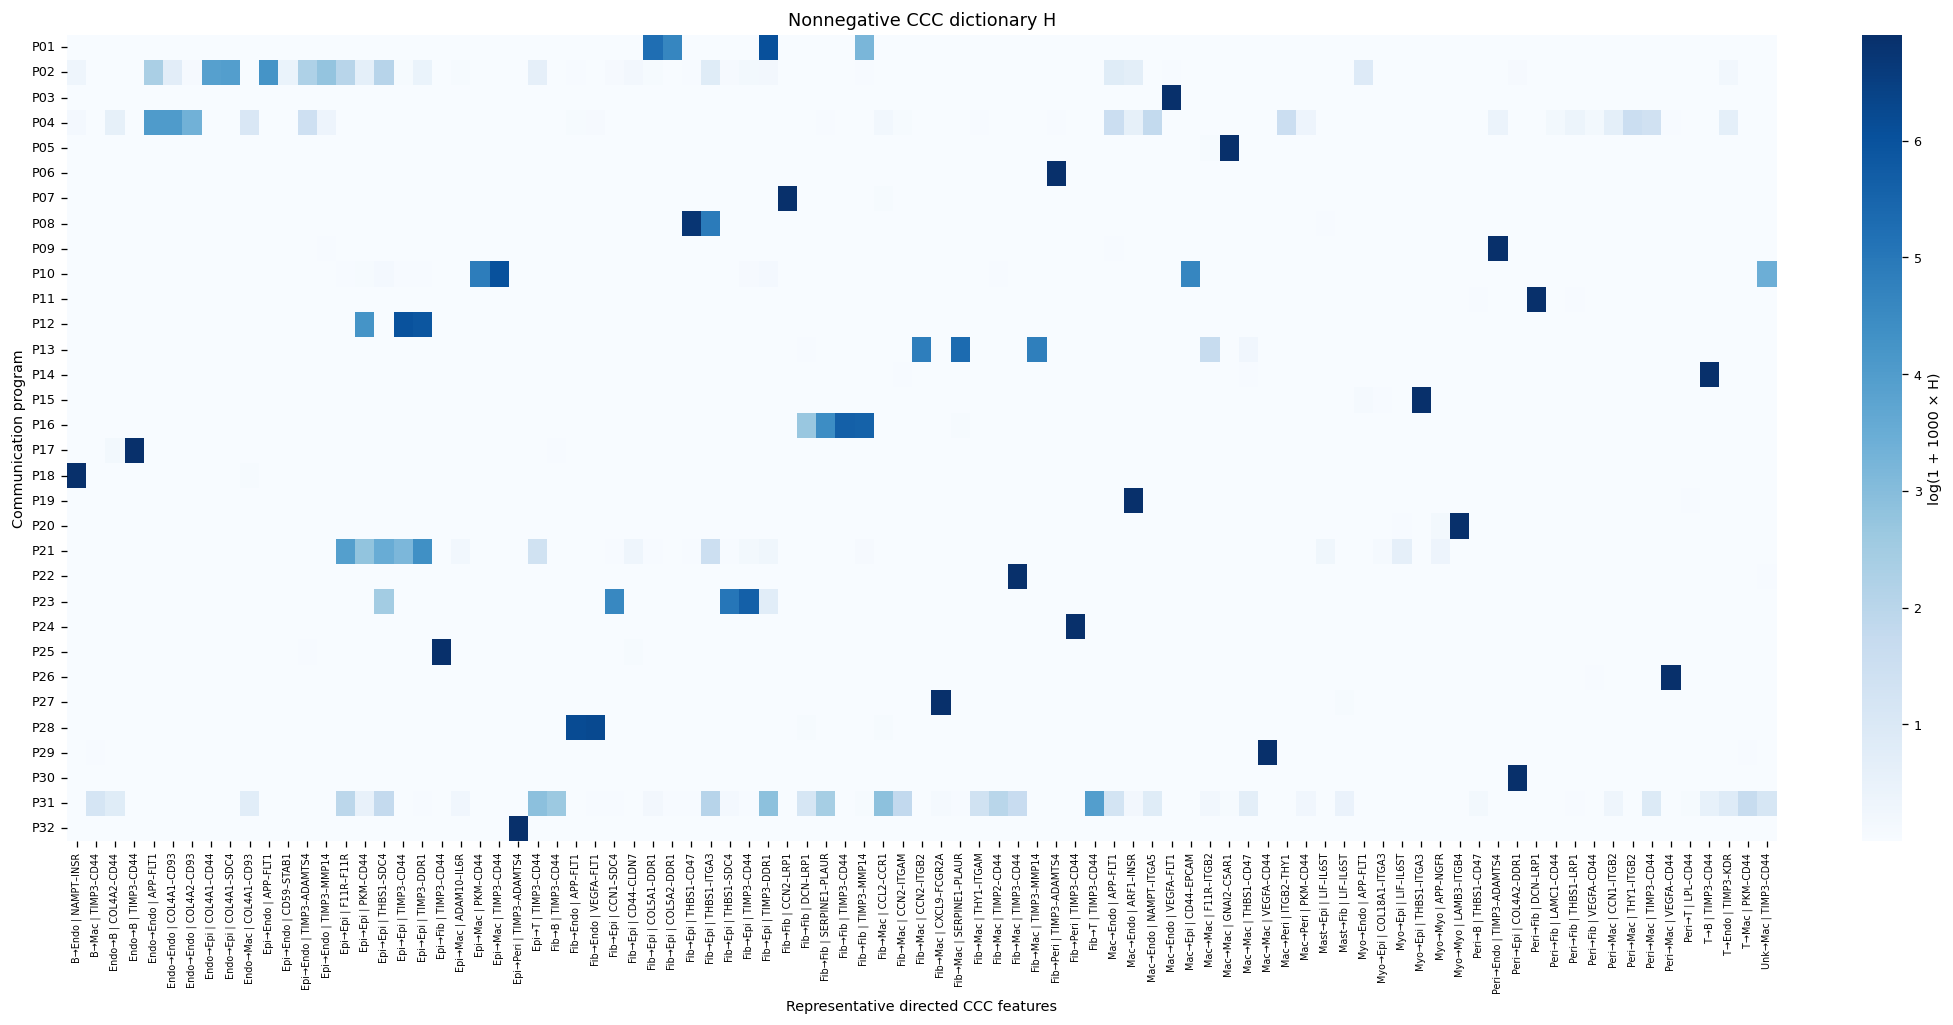

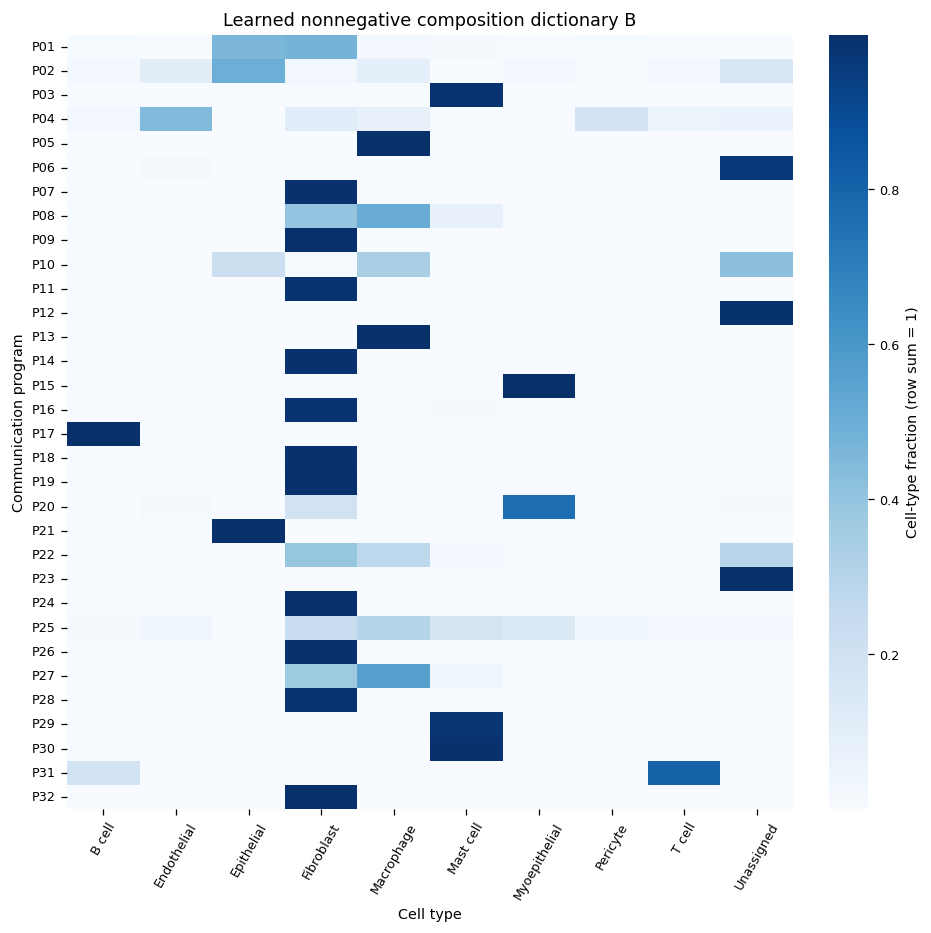

,program,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,907,Fibroblast → Epithelial | TIMP3–DDR1,Fibroblast,Epithelial,TIMP3,DDR1,0.427347
1,1,2,865,Fibroblast → Epithelial | COL5A1–DDR1,Fibroblast,Epithelial,COL5A1,DDR1,0.191909
2,1,3,867,Fibroblast → Epithelial | COL5A2–DDR1,Fibroblast,Epithelial,COL5A2,DDR1,0.102358
3,1,4,884,Fibroblast → Epithelial | MMP14–DDR1,Fibroblast,Epithelial,MMP14,DDR1,0.071222
4,1,5,866,Fibroblast → Epithelial | COL5A1–ITGA2,Fibroblast,Epithelial,COL5A1,ITGA2,0.037976
15,2,1,459,Epithelial → Endothelial | APP–FLT1,Epithelial,Endothelial,APP,FLT1,0.068598
16,2,2,156,Endothelial → Epithelial | COL4A1–SDC4,Endothelial,Epithelial,COL4A1,SDC4,0.051210
17,2,3,153,Endothelial → Epithelial | COL4A1–CD44,Endothelial,Epithelial,COL4A1,CD44,0.048526
18,2,4,158,Endothelial → Epithelial | COL4A2–DDR1,Endothelial,Epithelial,COL4A2,DDR1,0.044633
19,2,5,154,Endothelial → Epithelial | COL4A1–CD47,Endothelial,Epithelial,COL4A1,CD47,0.043208


In [5]:
fig,usage=report.program_usage();show(fig);display(usage)
show(report.dictionary_heatmap())
show(report.composition_dictionary())
display(pd.read_csv(OUTPUT/'programs/top_ccc.csv').groupby('program').head(5))

## 5. Select K = 4–15 and identify communication-defined niches

Clustering is based on communication-program mixture and activity from Z. K is fitted on training blocks and selected on validation blocks; test blocks are reserved for final diagnostics. Seed stability refers to clustering seeds, not independent GNN retraining.

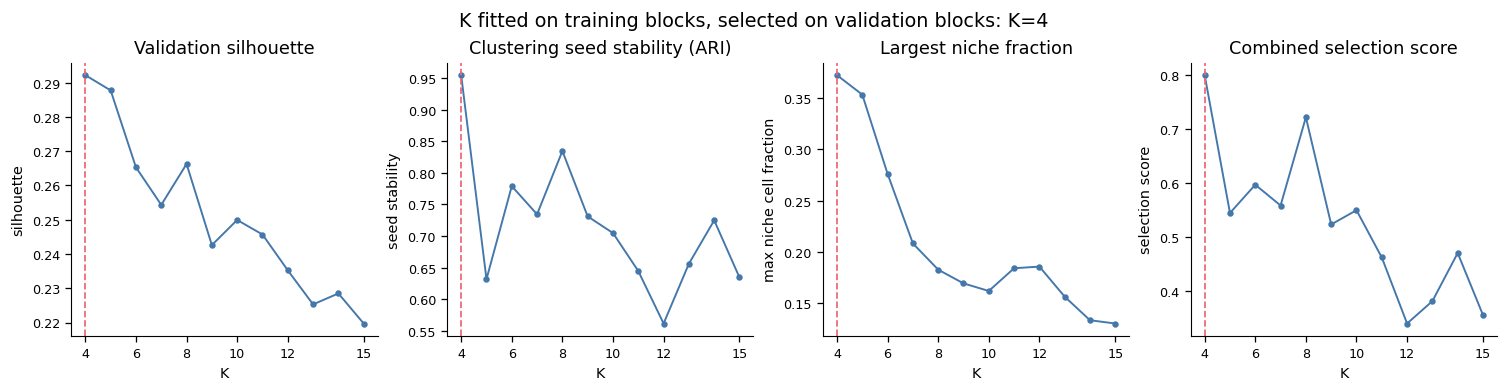

,K,silhouette,seed_stability,max_niche_cell_fraction,tiny_niche_fraction,active_niches,selection_score,eligible,selected
0,4,0.292184,0.954633,0.3726,0.0,4,0.800000,True,True
1,5,0.287738,0.631666,0.3536,0.0,5,0.544678,True,False
2,6,0.265292,0.778953,0.2762,0.0,6,0.596980,True,False
3,7,0.254334,0.734333,0.2082,0.0,7,0.558505,True,False
4,8,0.266268,0.834528,0.1826,0.0,8,0.721936,True,False
5,9,0.242599,0.731061,0.1692,0.0,9,0.523382,True,False
6,10,0.249931,0.704686,0.1618,0.0,10,0.549826,True,False
7,11,0.245687,0.644530,0.1840,0.0,11,0.462198,True,False
8,12,0.235249,0.561482,0.1856,0.0,12,0.339888,True,False
9,13,0.225294,0.656099,0.1562,0.0,13,0.381378,True,False


In [6]:
show(report.k_selection())
display(report.selection)

## 6. Tissue-space maps, individual niches, composition and enrichment

All cell centers use original micrometer coordinates. Enrichment is descriptive within one tissue; overlapping microenvironments are not independent biological replicates. The local composition plot uses the exact pair-weighted composition target.

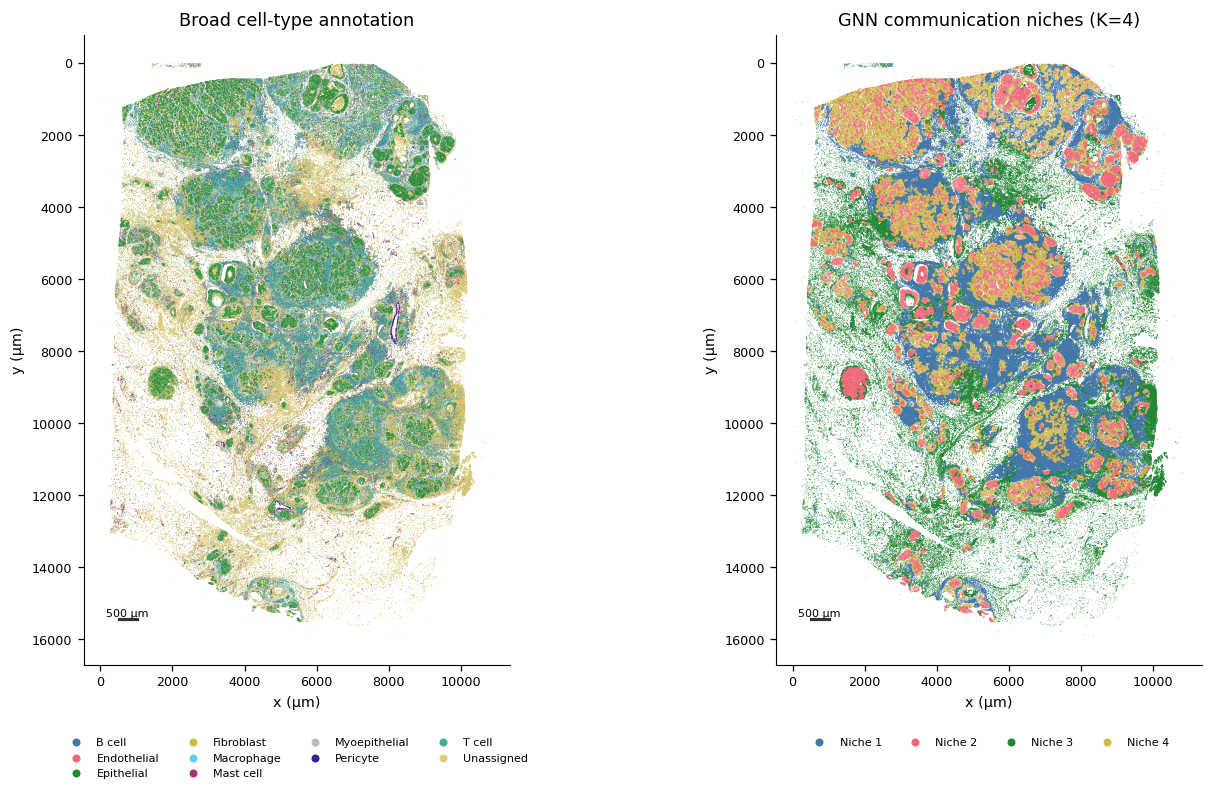

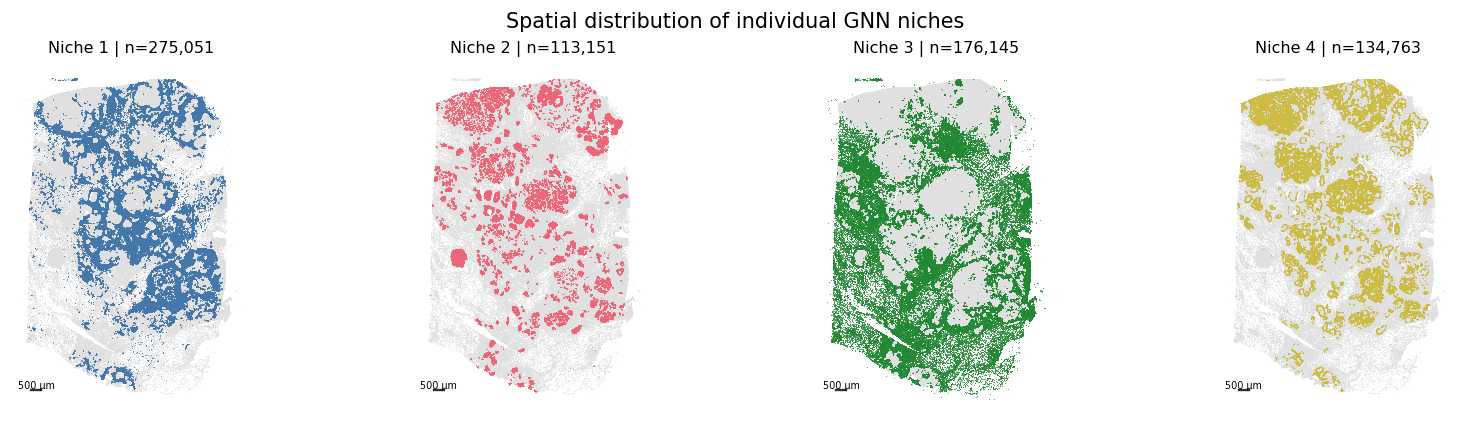

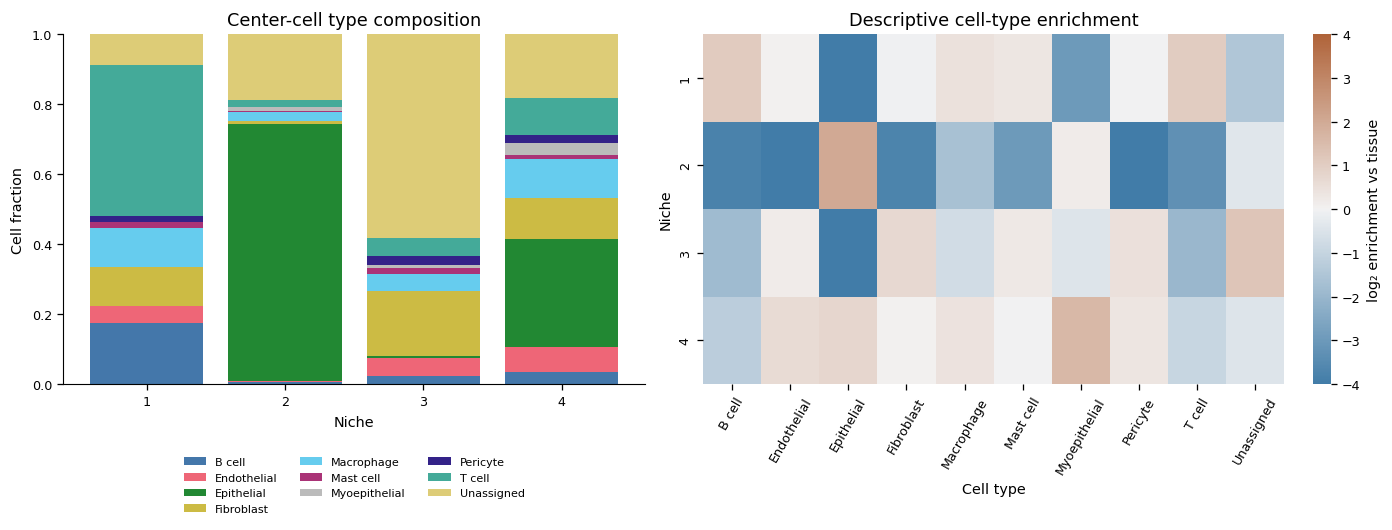

cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,0.175440,0.047242,0.000967,0.110678,0.112503,0.015710,0.001360,0.018138,0.429200,0.088762
2,0.005992,0.002103,0.735433,0.008688,0.025621,0.001600,0.012170,0.000901,0.020857,0.186636
3,0.022686,0.051810,0.007193,0.185836,0.048704,0.015135,0.007851,0.025740,0.051554,0.583491
4,0.034950,0.072260,0.308527,0.117458,0.109615,0.012422,0.032984,0.023144,0.106127,0.182513


cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,1.089444,0.041272,-7.544206,-0.047900,0.459611,0.312791,-2.994149,-0.007175,1.061226,-1.478385
2,-3.782123,-4.447364,2.025028,-3.719025,-1.674928,-2.982253,0.166777,-4.336315,-3.301751,-0.406179
3,-1.861615,0.174413,-4.650643,0.699757,-0.748214,0.259041,-0.465400,0.497771,-1.996242,1.238302
4,-1.238128,0.654387,0.771832,0.037881,0.422092,-0.025976,1.605182,0.344415,-0.954623,-0.438404


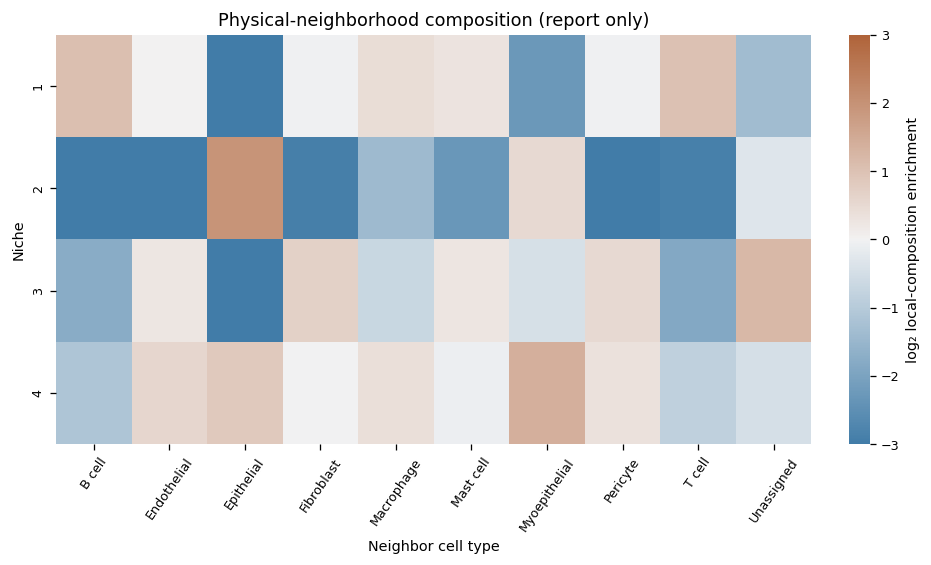

In [7]:
show(report.spatial_overview())
show(report.each_niche())
fig,fraction,enrichment=report.composition();show(fig)
display(fraction)
display(enrichment)
show(report.local_composition())

## 7. Niche × program activity and representative communication

Activity heatmaps use mean Z of assigned cells. Representative niche CCC profiles use training-block soft program contributions, preserving the trained H interpretation. Cell composition is an explicit auxiliary task, so composition correspondence is expected and does not establish a distinct biological mechanism.

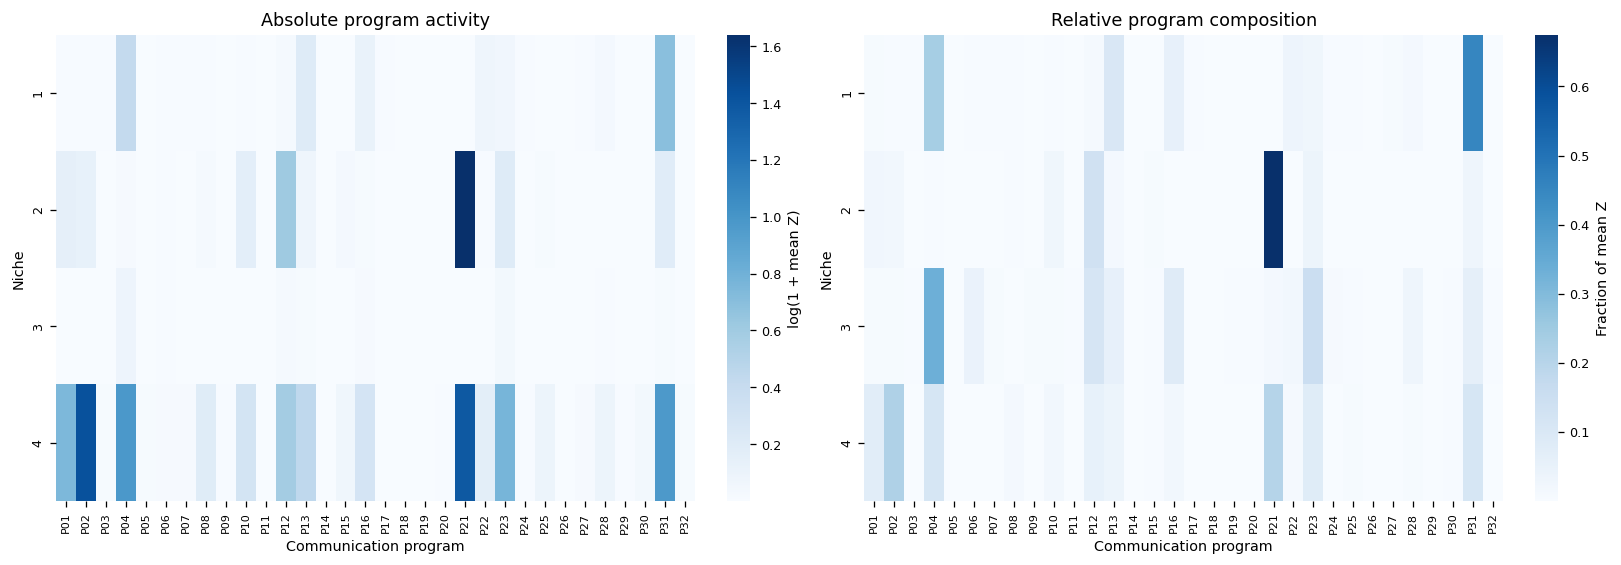

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,...,P23,P24,P25,P26,P27,P28,P29,P30,P31,P32
1,0.012562,0.010599,0.006916,0.526031,0.005765,0.010991,0.010614,0.006616,0.004935,0.009256,...,0.059824,0.007826,0.006010,0.001035,0.012286,0.034278,0.005670,0.003010,1.001324,0.001467
2,0.159093,0.139159,0.001513,0.023437,0.003743,0.006577,0.001012,0.028375,0.000452,0.176895,...,0.232742,0.001518,0.013092,0.000249,0.001176,0.001764,0.002951,0.002843,0.209988,0.002961
3,0.001798,0.001838,0.000814,0.087447,0.000618,0.011942,0.001542,0.000553,0.001533,0.001548,...,0.039905,0.002299,0.000858,0.000524,0.000534,0.008191,0.000634,0.000798,0.016397,0.001352
4,1.114912,3.176972,0.018879,1.656462,0.015748,0.020616,0.022739,0.218493,0.007810,0.346417,...,1.162380,0.010212,0.096321,0.001085,0.023771,0.098571,0.009052,0.040570,1.640586,0.017755


,niche,cells,leading_programs,representative_CCC
0,1,275051,"P31, P04, P13",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → T cell | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Fibroblast → Fibroblast | TIMP3–...
1,2,113151,"P21, P12, P02",Epithelial → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Epithelial → Epithelial | F11R–F11R; Epithelial → Epithelial | THBS1–S...
2,3,176145,"P04, P31, P23",Epithelial → Epithelial | TIMP3–CD44; Epithelial → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–CD44; Fibroblast → Macrophage | TIMP3–...
3,4,134763,"P21, P02, P04",Epithelial → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Fibroblast → Epithelial | TIMP3–...


Niche 1: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,977,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.036043
1,1,2,1112,Fibroblast → T cell | TIMP3–CD44,Fibroblast,T cell,TIMP3,CD44,0.022636
2,1,3,968,Fibroblast → Macrophage | SERPINE1–PLAUR,Fibroblast,Macrophage,SERPINE1,PLAUR,0.020818
3,1,4,932,Fibroblast → Fibroblast | TIMP3–CD44,Fibroblast,Fibroblast,TIMP3,CD44,0.015158
4,1,5,933,Fibroblast → Fibroblast | TIMP3–MMP14,Fibroblast,Fibroblast,TIMP3,MMP14,0.014756


Niche 2: representative sender–receiver–LR


...

Niche 3: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
30,3,1,573,Epithelial → Epithelial | TIMP3–CD44,Epithelial,Epithelial,TIMP3,CD44,0.030816
31,3,2,574,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.030544
32,3,3,906,Fibroblast → Epithelial | TIMP3–CD44,Fibroblast,Epithelial,TIMP3,CD44,0.028026
33,3,4,977,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.024436
34,3,5,1094,Fibroblast → Pericyte | TIMP3–ADAMTS4,Fibroblast,Pericyte,TIMP3,ADAMTS4,0.020891


Niche 4: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
45,4,1,574,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.035791
46,4,2,907,Fibroblast → Epithelial | TIMP3–DDR1,Fibroblast,Epithelial,TIMP3,DDR1,0.033277
47,4,3,573,Epithelial → Epithelial | TIMP3–CD44,Epithelial,Epithelial,TIMP3,CD44,0.026629
48,4,4,906,Fibroblast → Epithelial | TIMP3–CD44,Fibroblast,Epithelial,TIMP3,CD44,0.021032
49,4,5,977,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.014245


,Diagnostic
composition_undefined_centers,17
composition_to_Z_test_R2,0.398852
composition_only_niche_test_accuracy,0.872384
dominant_niche_test_fraction,0.386418
test_spatial_neighbor_agreement,0.936254
effective_programs,11.797546
maximum_dictionary_cosine,0.542709
dictionary_entropy,1.111073
interpretation,"Single-tissue association diagnostics; composition is auxiliary supervision, not evidence of causality or phenotype."


In [8]:
fig,activity=report.niche_programs();show(fig);display(activity)
overview,ccc=report.interpretation();display(overview)
for niche in range(1,report.k+1):
    print(f'Niche {niche}: representative sender–receiver–LR')
    display(ccc.loc[ccc.niche==niche].head(5))
display(pd.Series(json.loads((OUTPUT/'diagnostics.json').read_text())).to_frame('Diagnostic'))

## 8. Comparison with archived CCC-vector AE

Archived AE weights/results remain unchanged. Spatial maps and cell assignment correspondence are descriptive: the archived model used overlapping random folds and a narrower CCC feature universe. This comparison does not establish comparative generalization or phenotype associations.

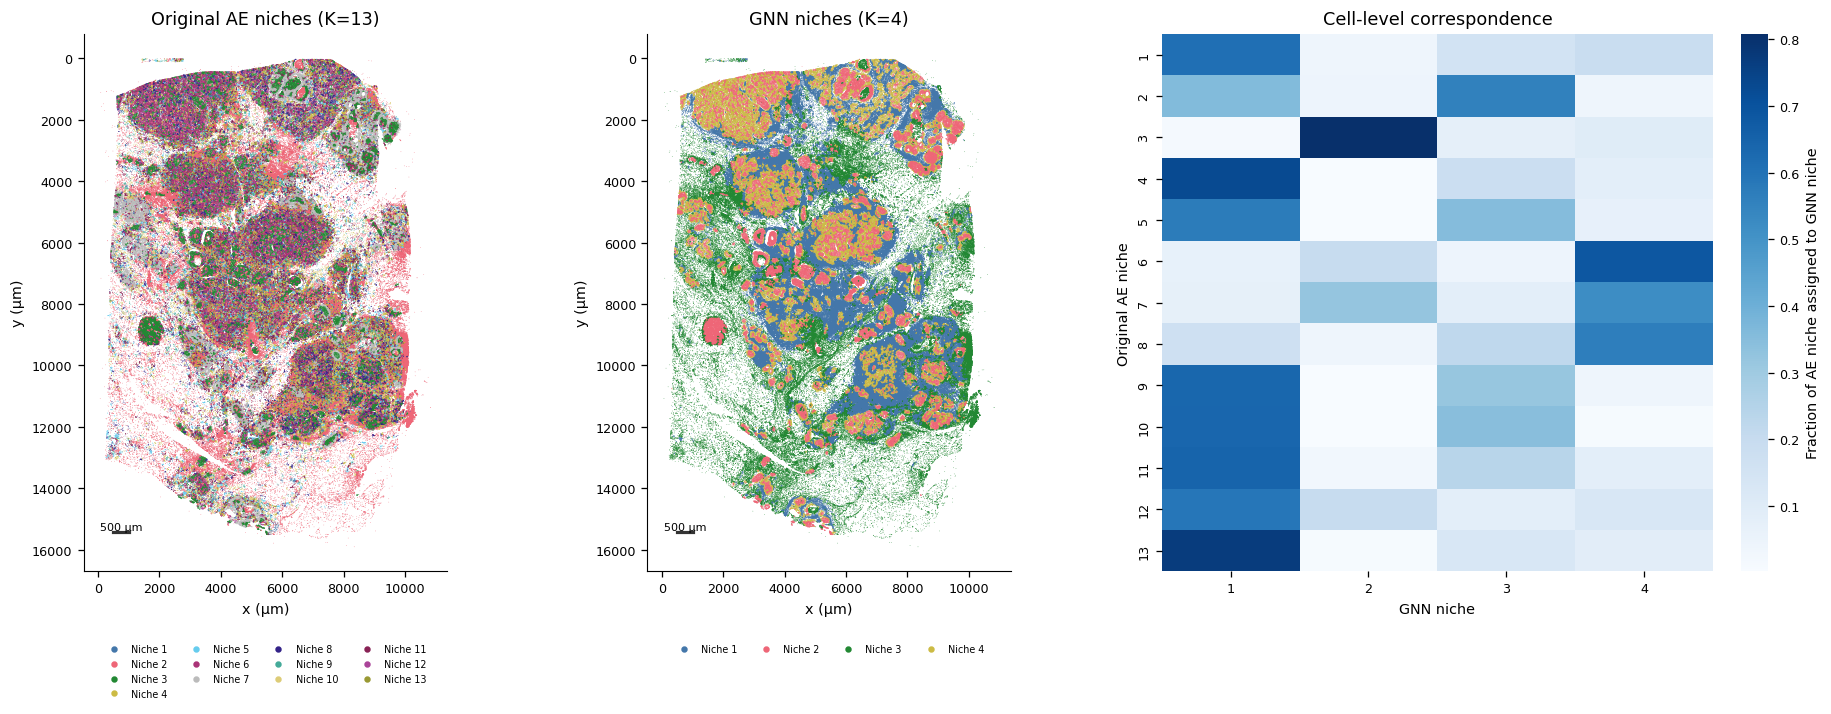

,Value
Cells,699110
Original AE K,13
GNN K,4
Adjusted Rand index,0.146424
Normalized mutual information,0.236314
Comparison scope,Descriptive same-tissue correspondence; original AE used overlapping random folds


Model arrays, native CCC reconstruction, composition prediction, records, tables and PNG/PDF: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_composition_weak_expr05


In [9]:
fig,comparison=report.comparison();show(fig);display(comparison)
print('Model arrays, native CCC reconstruction, composition prediction, records, tables and PNG/PDF:',OUTPUT)